In [2]:
import sys
import numpy as np

print(sys.executable)
print(np.__version__)

/usr/local/python/3.14.2/bin/python
2.5.4


In [3]:
from pathlib import Path
import tifffile
import matplotlib.pyplot as plt

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

image_dir = project_root / "data/raw/bbbc039/images/images"
image_paths = sorted(image_dir.glob("*.tif"))

print("Number of images:", len(image_paths))

Number of images: 200


In [4]:
image = tifffile.imread(image_paths[0])

print("Shape:", image.shape)
print("Data type:", image.dtype)
print("First Pixel:", image[0,0])

Shape: (520, 696)
Data type: uint16
First Pixel: 145


In [5]:
# Task 1: Get the pixel value at row 100, column 200
print(image[99, 199])

# Task 2: Get the total number of pixels
print(image.size)

# Task 3: Get the center pixel value
center_row = image.shape[0] // 2
center_col = image.shape[1] // 2

print(image[center_row, center_col])

164
361920
161


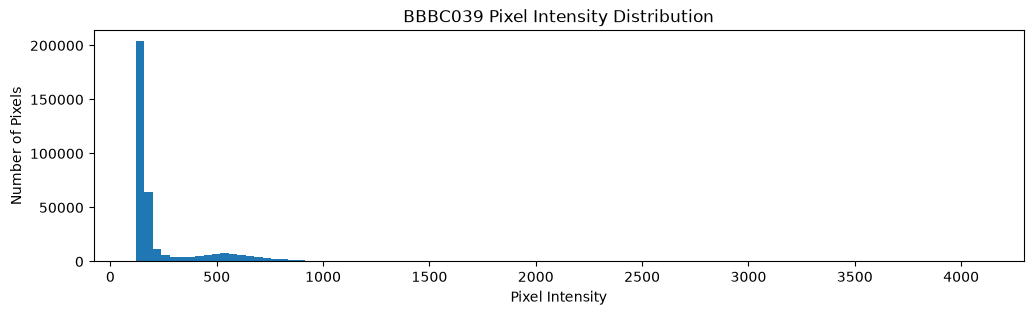

In [6]:
plt.figure(figsize=(12,3))

plt.hist(image.ravel(), bins= (100))

plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.title("BBBC039 Pixel Intensity Distribution")

plt.show()

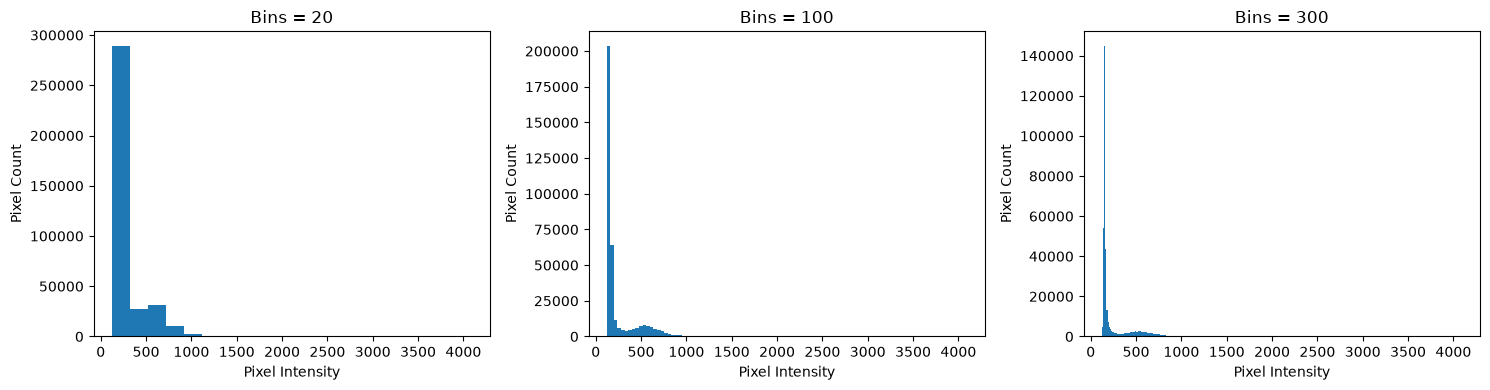

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, bins in zip(axes, [20, 100, 300]):
    ax.hist(image.ravel(), bins=bins)
    ax.set_title(f"Bins = {bins}")
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

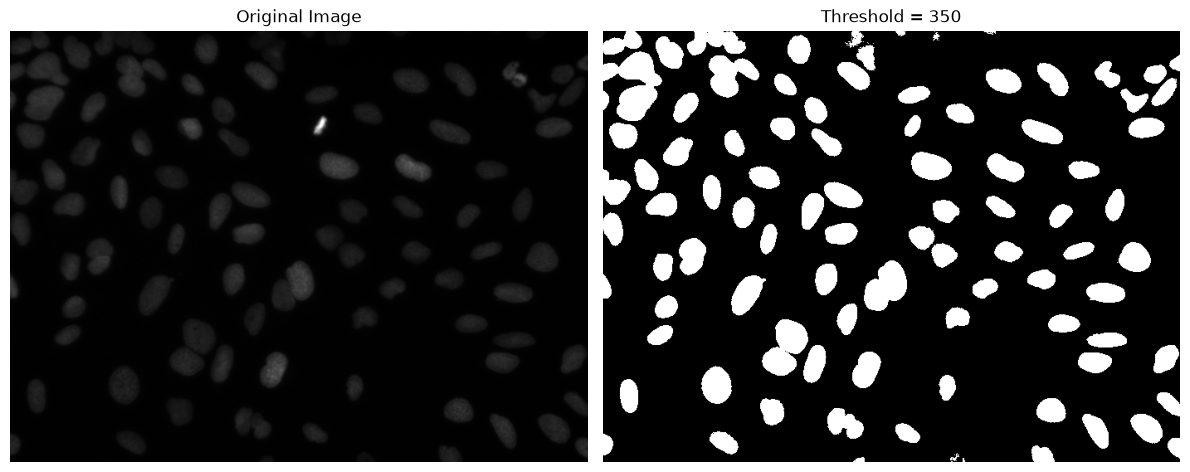

In [8]:
threshold = 350
mask = image > threshold

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title(f"Threshold = {threshold}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from skimage.filters import threshold_otsu

otsu_threshold = threshold_otsu(image)

print("Manual Threshold:", 350)
print("Otsu Threshold:", otsu_threshold)

Manual Threshold: 350
Otsu Threshold: 395


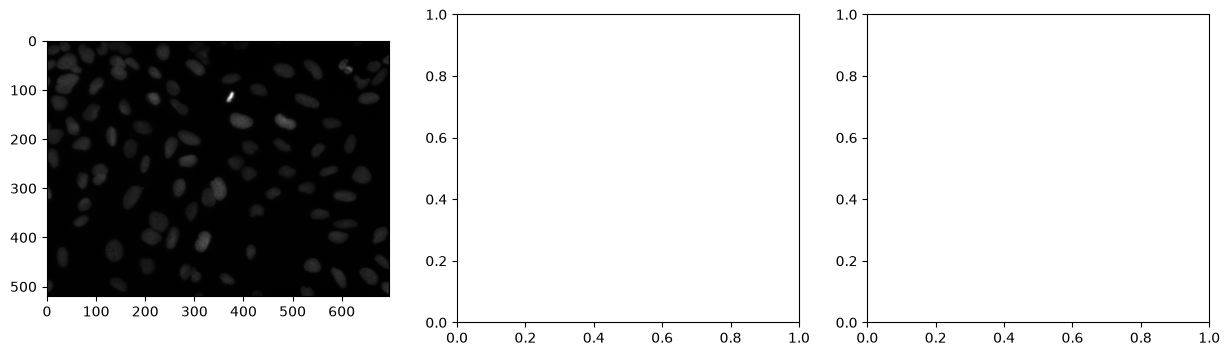

In [10]:
manual_mask = image > 350
ostu_mask = image > otsu_threshold

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(image, cmap="gray")